In [ ]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.impute import SimpleImputer

Ex 2
X is the treatment indicator
Y is the outcome
Z is an additional variable that separates our data into subgroups.
In Z = 1: X = 1 & Y = 1, 15. X = 1 & Y = 0, 25. X = 0 & Y = 1, 5. X = 0 & Y = 0, 10
In Z = 0: X = 1 & Y = 1, 20. X = 1 & Y = 0, m. X = 0 & Y = 1, 20. X = 0 & Y = 0, 10
So
Z = 1
treated:   success 15, failure 25 = 15/40
untreated: success 5,  failure 10 = 5/15 = 1/3

15/40 > 1/3, so treatment has a higher success rate than untreated

Z = 0
treated:   success 20, failure m = 20/(20+m)
untreated: success 20,  failure 10 = 20/30 = 2/3

20/(20+m) > 2/3, for the treatment to have a higher success rate than untreated

AoS 16.4 states Simpsons Paradox, when ignoring Z and combining everyone:
P(Y=1 | X=1) < P(Y=I | X=0)

treated:   success 35, failure 25+m = 35/(60+m)
untreated: success 25,  failure 20 = 25/45

In [10]:
valid_m = []

for m in range(100):
    z0_fraction = 20/(20+m)
    z_combined_fraction = 35/(60+m)
    if z0_fraction > 2/3 and z_combined_fraction < 25/45:
        valid_m.append(m)

print("Valid values of m:", min(valid_m), max(valid_m))

Valid values of m: 4 9


In [16]:
for m in [3, 4, 9, 10]:
    z0_fraction = 20/(20+m)
    combined_fraction = 35/(60+m)

    print(m, z0_fraction > 2/3, combined_fraction < 25/45)

3 True False
4 True True
9 True True
10 False True


Ex 3.

In [2]:
data = pd.read_csv("toy_missing.txt", sep="\t", header=None, names=["X1", "X2", "X3", "X4"])
#print(data.columns)
print("X1:",data["X1"].mean())
print("X2:",data["X2"].mean())
print("X3:",data["X3"].mean())
print("X4:",data["X4"].mean())

X1: -0.037666
X2: -0.07960843373493975
X3: 0.3885646687697161
X4: 0.436472891566265


In [3]:
# Ex 3.2
dropna_data = data.dropna()
#data.head()
print("X1:",dropna_data["X1"].mean())
print("X2:",dropna_data["X2"].mean())
print("X3:",dropna_data["X3"].mean())
print("X4:",dropna_data["X4"].mean())

X1: 0.5573614457831325
X2: 0.45115662650602406
X3: 0.4748975903614458
X4: 0.5823373493975903


Results using only complete observations differ from the previous ex by making the means a lot bigger. This is because complete case analysis can produced biased estimateds when missingess depends on them

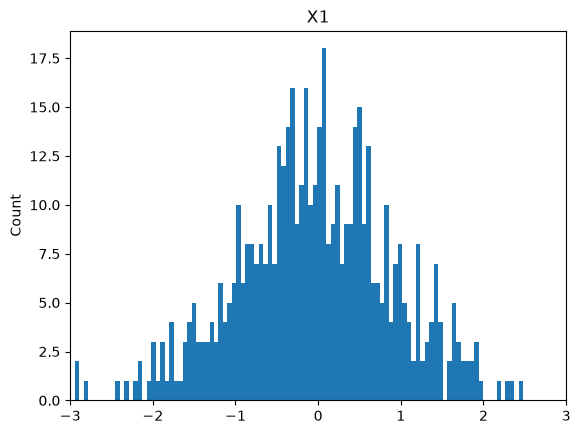

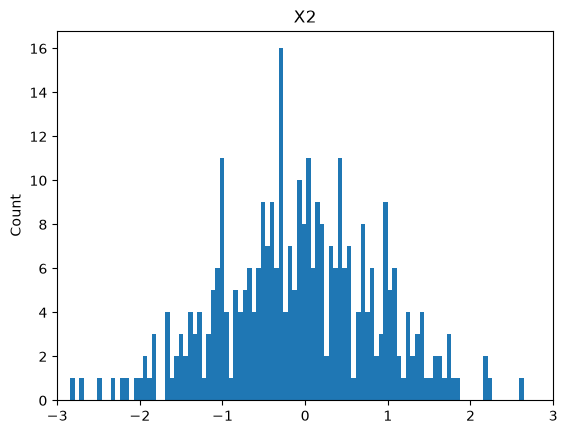

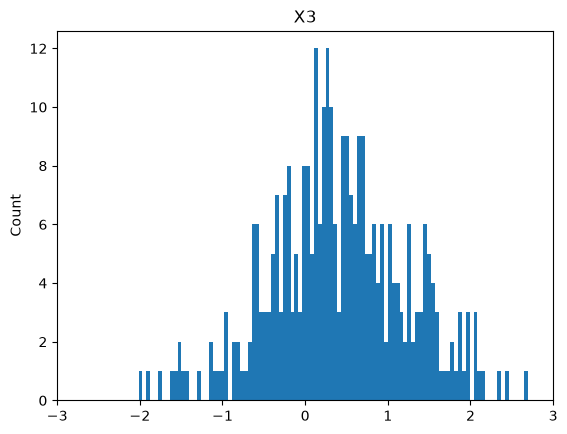

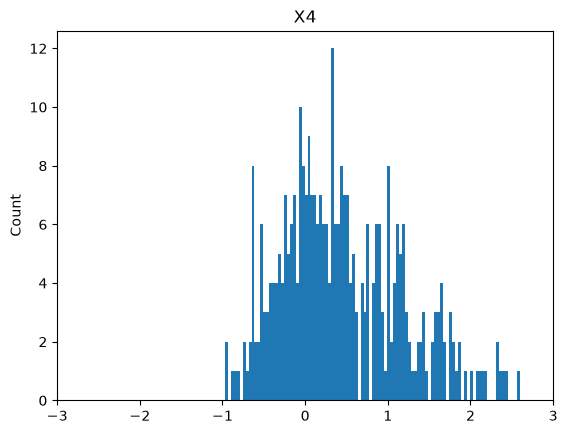

In [4]:
# Ex 3.3
for column in data.columns:
    plt.hist(data[column].dropna(), bins=100)
    plt.title(column)
    plt.ylabel("Count")
    plt.xlim(-3, 3)
    plt.show()

We use X1 as a reference point
X2 (MCAR) holds the same shape as X1 but with fewer points
X3 (MAR) shape changed indirectly through another observed variable
X4 (MNAR) some variable are more likely to dissappear so shape has changed directly
ITS F = X2,X4,X1,X3

In [5]:
# Ex 3.4
dropna_data_corr = dropna_data.corr()
print(dropna_data_corr)

          X1        X2        X3        X4
X1  1.000000  0.667494  0.592397  0.633576
X2  0.667494  1.000000  0.340384  0.332393
X3  0.592397  0.340384  1.000000  0.338525
X4  0.633576  0.332393  0.338525  1.000000


In [6]:
pairwise_corr = data.corr()
print(pairwise_corr)

          X1        X2        X3        X4
X1  1.000000  0.805627  0.651844  0.671106
X2  0.805627  1.000000  0.312451  0.443313
X3  0.651844  0.312451  1.000000  0.388432
X4  0.671106  0.443313  0.388432  1.000000


Pairwise correleation uses more observations for each pair so the correlation differs. X2 (MCAR) difference are because of random smapling variability. X3 and X4 (MAR, MNAR) are depended on some variable or missing value itself so differences can be caused by the missingess.

In [7]:
# Ex 3.5
pair = data[["X1", "X2"]].dropna()

X = sm.add_constant(pair["X1"])
y = pair["X2"]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     X2   R-squared:                       0.649
Model:                            OLS   Adj. R-squared:                  0.648
Method:                 Least Squares   F-statistic:                     610.3
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           5.06e-77
Time:                        11:02:43   Log-Likelihood:                -278.36
No. Observations:                 332   AIC:                             560.7
Df Residuals:                     330   BIC:                             568.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0007      0.031     -0.022      0.9

In [8]:
pair = data[["X1", "X3"]].dropna()

X = sm.add_constant(pair["X1"])
y = pair["X3"]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     X3   R-squared:                       0.425
Model:                            OLS   Adj. R-squared:                  0.423
Method:                 Least Squares   F-statistic:                     232.7
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           9.91e-40
Time:                        11:02:43   Log-Likelihood:                -299.92
No. Observations:                 317   AIC:                             603.8
Df Residuals:                     315   BIC:                             611.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0189      0.043      0.444      0.6

In [9]:
pair = data[["X1", "X4"]].dropna()

X = sm.add_constant(pair["X1"])
y = pair["X4"]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     X4   R-squared:                       0.450
Model:                            OLS   Adj. R-squared:                  0.449
Method:                 Least Squares   F-statistic:                     270.4
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           8.39e-45
Time:                        11:02:43   Log-Likelihood:                -268.23
No. Observations:                 332   AIC:                             540.5
Df Residuals:                     330   BIC:                             548.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2458      0.032      7.668      0.0

In [10]:
# Ex 4
gss_data = pd.read_csv("gss2010.txt", sep="\t")
gss_data.head()

,SEX,AGE,RACE,DEGREE,HAPPY,POLVIEWS,nAGE,ISUNHAPPY
0,MALE,31,OTHER,BACHELOR,PRETTY HAPPY,SLIGHTLY LIBERAL,31.0,False
1,FEMALE,23,WHITE,BACHELOR,NOT TOO HAPPY,LIBERAL,23.0,True
2,FEMALE,71,BLACK,LT HIGH SCHOOL,NOT TOO HAPPY,NaN,71.0,True
3,FEMALE,82,WHITE,LT HIGH SCHOOL,NOT TOO HAPPY,LIBERAL,82.0,True
4,FEMALE,78,BLACK,LT HIGH SCHOOL,VERY HAPPY,SLIGHTLY LIBERAL,78.0,False


In [11]:
used_cols = gss_data[["ISUNHAPPY", "SEX", "nAGE", "RACE", "DEGREE", "POLVIEWS"]]
#print(used_cols.head())
complete_data = used_cols.dropna()

complete_data["ISUNHAPPY"] = complete_data["ISUNHAPPY"].astype(int)

model = smf.logit("ISUNHAPPY ~ SEX + nAGE + RACE + DEGREE + POLVIEWS", data=complete_data).fit()
print(model.summary())

Optimization terminated successfully.
         Current function value: 0.409496
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              ISUNHAPPY   No. Observations:                 1969
Model:                          Logit   Df Residuals:                     1954
Method:                           MLE   Df Model:                           14
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                 0.03457
Time:                        11:02:43   Log-Likelihood:                -806.30
converged:                       True   LL-Null:                       -835.17
Covariance Type:            nonrobust   LLR p-value:                 2.905e-07
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                           -2.5075      0.343     -7.31

In [12]:
print(model.summary2().tables[1].to_string())

                                     Coef.  Std.Err.         z         P>|z|    [0.025    0.975]
Intercept                        -2.507515  0.343041 -7.309672  2.677945e-13 -3.179862 -1.835168
SEX[T.MALE]                       0.184562  0.129192  1.428595  1.531207e-01 -0.068648  0.437773
RACE[T.OTHER]                    -0.018170  0.248427 -0.073140  9.416950e-01 -0.505077  0.468737
RACE[T.WHITE]                    -0.362574  0.171020 -2.120068  3.400028e-02 -0.697767 -0.027381
DEGREE[T.GRADUATE]                0.229964  0.298405  0.770645  4.409173e-01 -0.354899  0.814828
DEGREE[T.HIGH SCHOOL]             0.804846  0.214426  3.753486  1.743924e-04  0.384578  1.225114
DEGREE[T.JUNIOR COLLEGE]          0.661178  0.313280  2.110503  3.481509e-02  0.047161  1.275196
DEGREE[T.LT HIGH SCHOOL]          1.251467  0.243588  5.137644  2.782037e-07  0.774044  1.728890
POLVIEWS[T.EXTREMELY LIBERAL]    -0.035858  0.361059 -0.099314  9.208893e-01 -0.743521  0.671805
POLVIEWS[T.EXTRMLY CONSERVATIV

In [13]:
print(model.pvalues)

Intercept                           2.677945e-13
SEX[T.MALE]                         1.531207e-01
RACE[T.OTHER]                       9.416950e-01
RACE[T.WHITE]                       3.400028e-02
DEGREE[T.GRADUATE]                  4.409173e-01
DEGREE[T.HIGH SCHOOL]               1.743924e-04
DEGREE[T.JUNIOR COLLEGE]            3.481509e-02
DEGREE[T.LT HIGH SCHOOL]            2.782037e-07
POLVIEWS[T.EXTREMELY LIBERAL]       9.208893e-01
POLVIEWS[T.EXTRMLY CONSERVATIVE]    7.932567e-02
POLVIEWS[T.LIBERAL]                 6.013497e-01
POLVIEWS[T.MODERATE]                7.488828e-01
POLVIEWS[T.SLGHTLY CONSERVATIVE]    3.893229e-01
POLVIEWS[T.SLIGHTLY LIBERAL]        6.235790e-01
nAGE                                1.035628e-01
dtype: float64


In [14]:
print(model.pvalues[model.pvalues < 0.01])

Intercept                   2.677945e-13
DEGREE[T.HIGH SCHOOL]       1.743924e-04
DEGREE[T.LT HIGH SCHOOL]    2.782037e-07
dtype: float64


In [15]:
# ex 4.b
# Numeric variable(s)
gss_data["ISUNHAPPY"] = gss_data["ISUNHAPPY"].astype(float)

imputed_data = gss_data[["ISUNHAPPY", "SEX", "nAGE", "RACE", "DEGREE", "POLVIEWS"]].copy()

mean_imputer = SimpleImputer(strategy="mean")
imputed_data[["nAGE"]] = mean_imputer.fit_transform(imputed_data[["nAGE"]])

mode_imputer = SimpleImputer(strategy="most_frequent")
imputed_data[["SEX", "RACE", "DEGREE", "POLVIEWS"]] = mode_imputer.fit_transform(imputed_data[["SEX", "RACE", "DEGREE", "POLVIEWS"]])

model = smf.logit("ISUNHAPPY ~ SEX + nAGE + RACE + DEGREE + POLVIEWS", data=imputed_data).fit()
print(model.summary())

Optimization terminated successfully.
         Current function value: 0.416489
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              ISUNHAPPY   No. Observations:                 2039
Model:                          Logit   Df Residuals:                     2024
Method:                           MLE   Df Model:                           14
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                 0.03608
Time:                        11:02:43   Log-Likelihood:                -849.22
converged:                       True   LL-Null:                       -881.01
Covariance Type:            nonrobust   LLR p-value:                 2.743e-08
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                           -2.3445      0.334     -7.02

In [16]:
print(model.pvalues[model.pvalues < 0.01])


Intercept                   2.130941e-12
RACE[T.WHITE]               7.079201e-03
DEGREE[T.HIGH SCHOOL]       2.172728e-04
DEGREE[T.LT HIGH SCHOOL]    1.081723e-07
dtype: float64
